In [17]:
import pandas as pd
from sklearn.datasets import load_iris

iris = load_iris()

df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["target"] = iris.target

print(df.head())


   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  


In [18]:
# Check dataset size
print("Shape:", df.shape)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()

print("Dataset shape:", df.shape)

Shape: (150, 5)

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64

Duplicate rows: 1
Dataset shape: (149, 5)


In [19]:
X = df[iris.feature_names]  # Input features
y = df["target"]             # Target

print("Features:", X.shape)
print("Target:", y.shape)

Features: (149, 4)
Target: (149,)


In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (119, 4)
Testing data: (30, 4)


In [21]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")

Feature scaling completed!


In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Create the model
model = LogisticRegression(max_iter=200)

# Train the model
model.fit(X_train_scaled, y_train)

# Predict the flower species
y_pred = model.predict(X_test_scaled)

# Check accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Logistic Regression Accuracy:", accuracy * 100, "%")

Logistic Regression Accuracy: 93.33333333333333 %


In [33]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

model = SVC()

model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
print(y_pred)
print("SVM Accuracy:", accuracy_score(y_test, y_pred) * 100, "%")

[1 1 2 0 2 1 1 0 2 2 0 0 0 1 2 0 2 0 2 0 1 2 0 0 1 1 2 2 2 1]
SVM Accuracy: 96.66666666666667 %


In [24]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

model = DecisionTreeClassifier(random_state=42)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred) * 100, "%")

Decision Tree Accuracy: 93.33333333333333 %


In [25]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

model = GaussianNB()

model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

print("Naive Bayes Accuracy:", accuracy_score(y_test, y_pred) * 100, "%")

Naive Bayes Accuracy: 93.33333333333333 %


In [26]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

model = MLPClassifier(
    hidden_layer_sizes=(10,),
    max_iter=2000,
    random_state=42
)

model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

print("Neural Network Accuracy:", accuracy_score(y_test, y_pred) * 100, "%")

Neural Network Accuracy: 93.33333333333333 %


In [27]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Create the model
model = KNeighborsClassifier(n_neighbors=5)

# Train the model
model.fit(X_train_scaled, y_train)

# Predict the species
y_pred = model.predict(X_test_scaled)

# Check accuracy
print("KNN Accuracy:", accuracy_score(y_test, y_pred) * 100, "%")

KNN Accuracy: 93.33333333333333 %


In [28]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Create the model
model = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the model
model.fit(X_train, y_train)

# Predict the species
y_pred = model.predict(X_test)

# Check accuracy
print("Random Forest Accuracy:", accuracy_score(y_test, y_pred) * 100, "%")

Random Forest Accuracy: 93.33333333333333 %


In [29]:

import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix
)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SVM": SVC(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Naive Bayes": GaussianNB(),
    "Neural Network": MLPClassifier(max_iter=2000, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42)
}

results = []

for name, model in models.items():

    if name in ["Decision Tree", "Random Forest"]:
        Xtr, Xte = X_train, X_test
    else:
        Xtr, Xte = X_train_scaled, X_test_scaled

    model.fit(Xtr, y_train)
    y_pred = model.predict(Xte)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, y_pred, average="weighted", zero_division=0),
        "F1-score": f1_score(y_test, y_pred, average="weighted", zero_division=0)
    })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))


              Model  Accuracy  Precision  Recall  F1-score
Logistic Regression    0.9333     0.9333  0.9333    0.9333
                SVM    0.9667     0.9697  0.9667    0.9666
      Decision Tree    0.9333     0.9333  0.9333    0.9333
        Naive Bayes    0.9333     0.9333  0.9333    0.9333
     Neural Network    0.9333     0.9364  0.9333    0.9332
                KNN    0.9333     0.9444  0.9333    0.9327
      Random Forest    0.9333     0.9333  0.9333    0.9333



 Logistic Regression
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


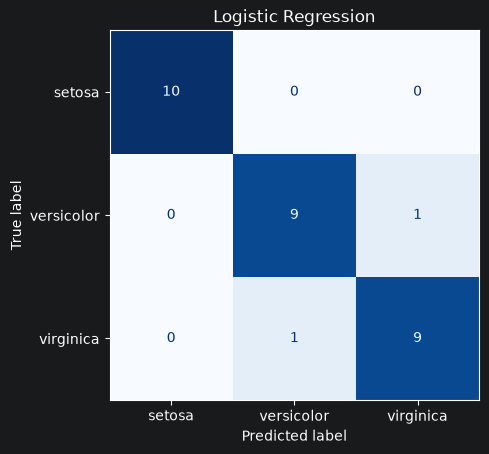


 SVM
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


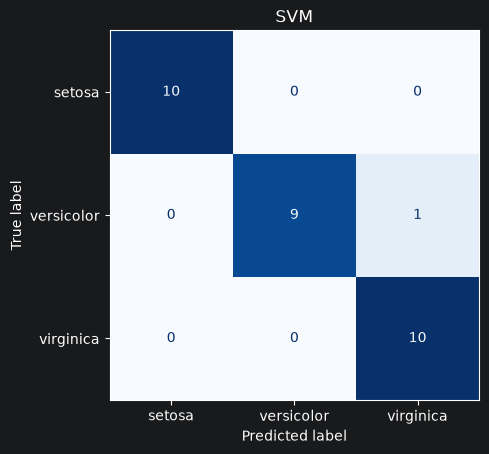


 Decision Tree
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


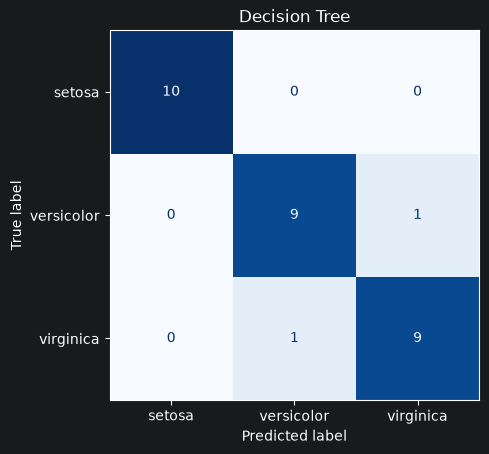


 Naive Bayes
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


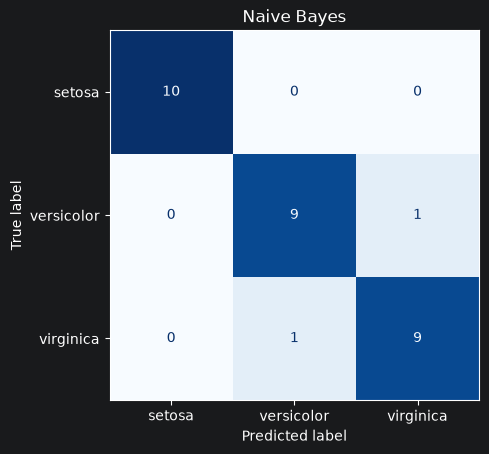


 Neural Network
[[ 9  1  0]
 [ 0  9  1]
 [ 0  0 10]]


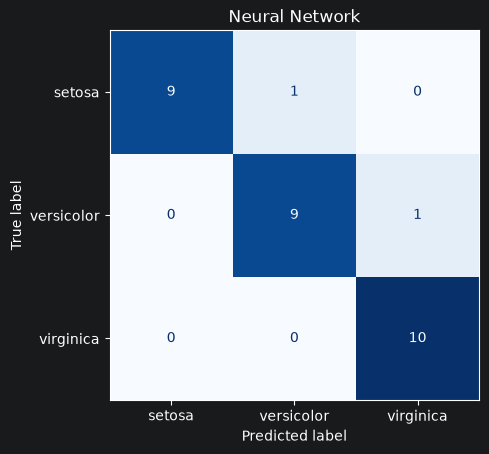


 KNN
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]


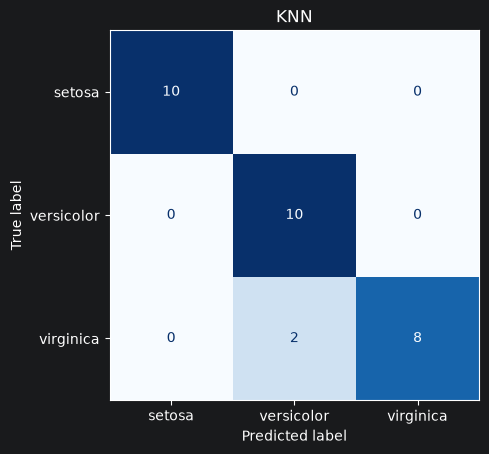


 Random Forest
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


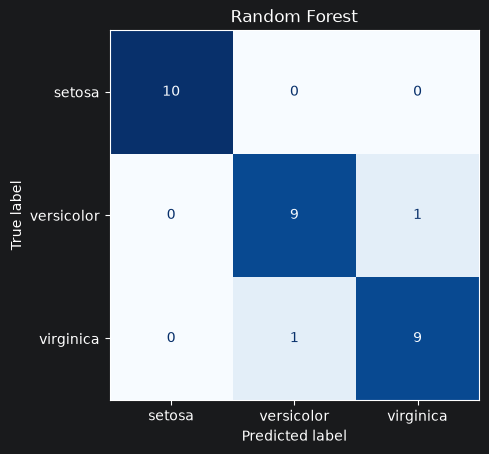

In [30]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for name, model in models.items():

    if name in ["Decision Tree", "Random Forest"]:
        Xte = X_test
    else:
        Xte = X_test_scaled

    y_pred = model.predict(Xte)

    print("\n", name)
    print(confusion_matrix(y_test, y_pred))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=iris.target_names,
        cmap="Blues",
        colorbar=False
    )

    plt.title(name)
    plt.show()

In [31]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

results = []

for name, model in models.items():

    if name in ["Decision Tree", "Random Forest"]:
        Xte = X_test
    else:
        Xte = X_test_scaled

    y_pred = model.predict(Xte)

    results.append({
        "Model": name,
        "Precision": precision_score(y_test, y_pred, average="weighted"),
        "Recall": recall_score(y_test, y_pred, average="weighted"),
        "F1-score": f1_score(y_test, y_pred, average="weighted")
    })

results_df = pd.DataFrame(results)
print(results_df.round(4).to_string(index=False))

              Model  Precision  Recall  F1-score
Logistic Regression     0.9333  0.9333    0.9333
                SVM     0.9697  0.9667    0.9666
      Decision Tree     0.9333  0.9333    0.9333
        Naive Bayes     0.9333  0.9333    0.9333
     Neural Network     0.9364  0.9333    0.9332
                KNN     0.9444  0.9333    0.9327
      Random Forest     0.9333  0.9333    0.9333


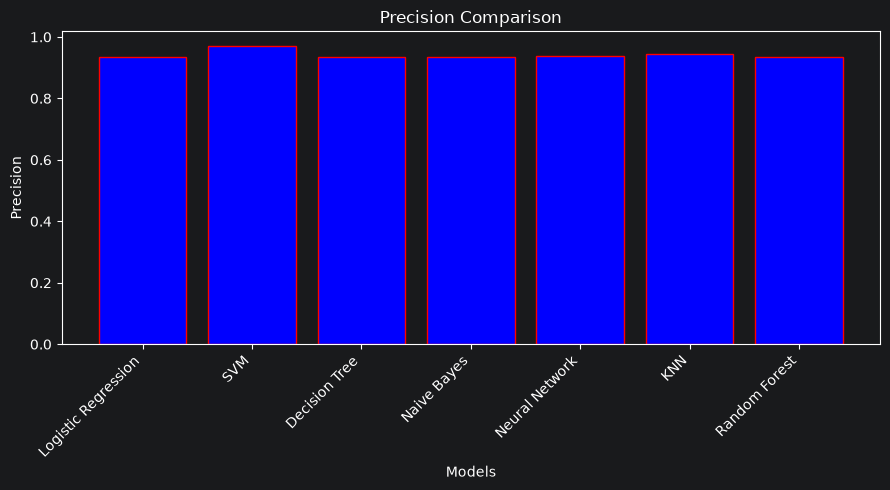

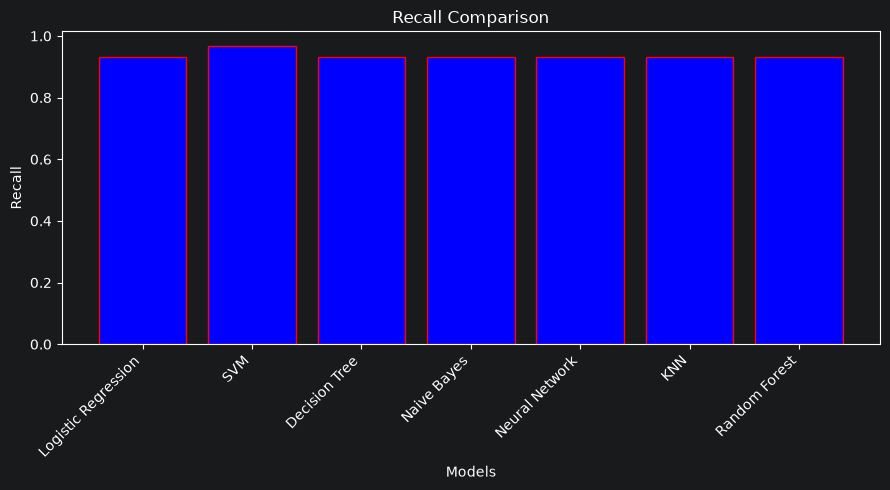

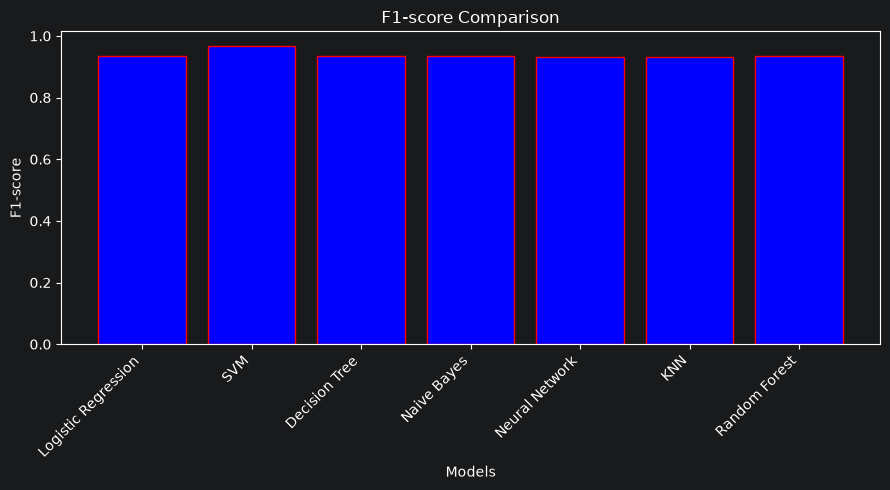

In [32]:
import matplotlib.pyplot as plt

for score in ["Precision", "Recall", "F1-score"]:
    plt.figure(figsize=(9, 5))
    plt.bar(results_df["Model"], results_df[score],
            color="blue", edgecolor="red")

    plt.title(score + " Comparison")
    plt.xlabel("Models")
    plt.ylabel(score)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()